In [3]:
import matplotlib.pyplot as mpl 
import pandas as pd 
import seaborn as sb 

df = pd.read_csv("student-mat.csv", sep=";")

Điểm số trung bình (G1, G2, G3) thay đổi như thế nào giữa các kỳ học?

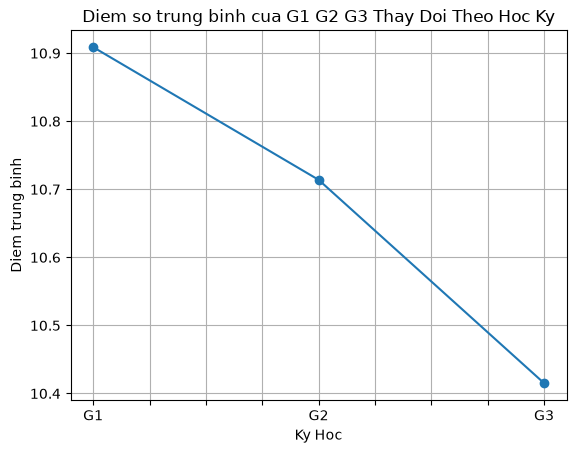

In [4]:
dtb = df[['G1','G2','G3']].mean()
dtb.plot(
    kind ='line', marker = 'o', title = 'Diem so trung binh cua G1 G2 G3 Thay Doi Theo Hoc Ky'
)
mpl.xlabel('Ky Hoc')
mpl.ylabel('Diem trung binh')
mpl.grid(True)
mpl.show()

 Sự khác biệt điểm trung bình giữa nam và nữ qua các kỳ học ra sao?

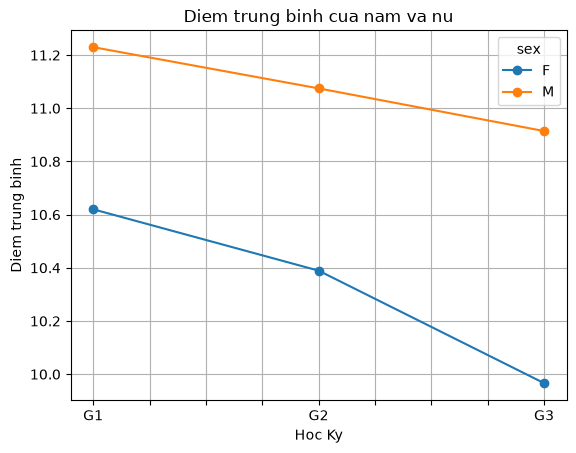

In [5]:
dtb = df.groupby('sex')[['G1', 'G2','G3']].mean().T
dtb.plot(
    kind = 'line', marker = 'o', title = 'Diem trung binh cua nam va nu'
)
mpl.xlabel('Hoc Ky')
mpl.ylabel('Diem trung binh')
mpl.grid(True)
mpl.show()

Thời gian học trung bình theo ngày học trong tuần (hoặc theo nhóm tuổi) 
có xu hướng tăng hay giảm?

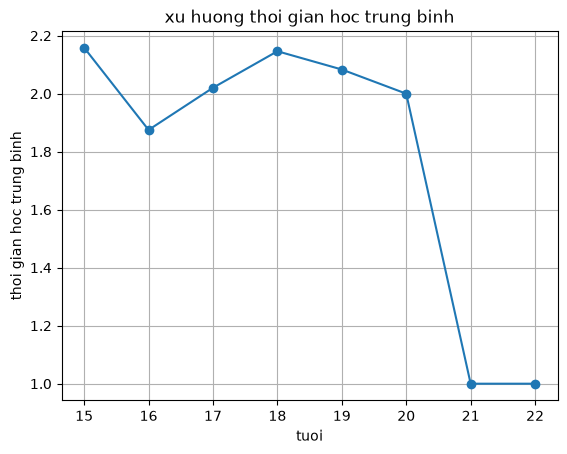

In [6]:
trend=df.groupby('age')['studytime'].mean()
trend.plot(
    kind = 'line', marker = 'o', title='xu huong thoi gian hoc trung binh'
)
mpl.xlabel('tuoi')
mpl.ylabel('thoi gian hoc trung binh')
mpl.grid(True)
mpl.show()

Trung bình điểm cuối kỳ (G3) theo giới tính hoặc trường học (school) 
khác nhau thế nào?

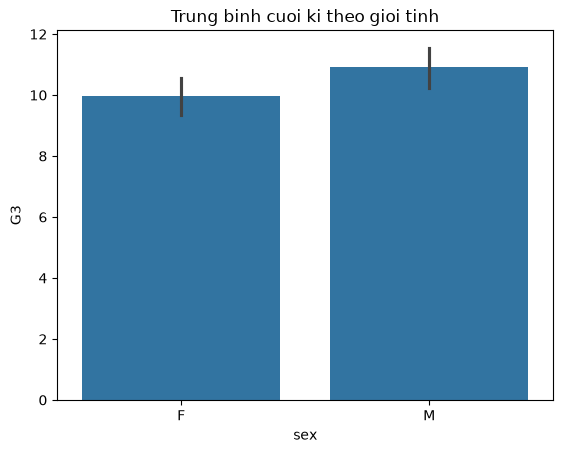

In [29]:
sb.barplot(data=df, x="sex", y="G3")
mpl.title("Trung binh cuoi ki theo gioi tinh")
mpl.show()


Học sinh ở đô thị (U) và nông thôn (R) có điểm trung bình khác nhau 
không?

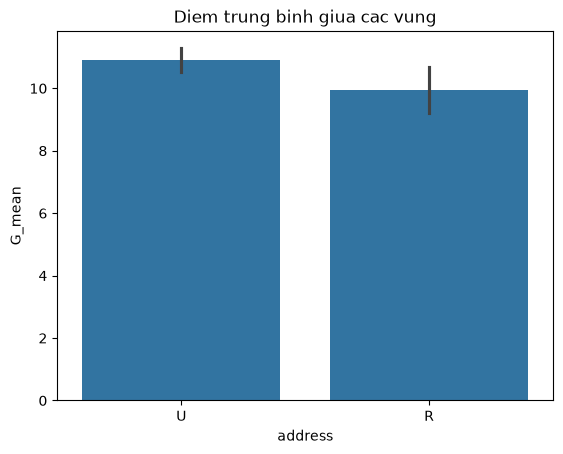

In [30]:
df['G_mean'] = df[['G1','G2','G3']].mean(axis =1)
sb.barplot (data=df, x='address', y='G_mean')
mpl.title('Diem trung binh giua cac vung')
mpl.show()

 Ảnh hưởng của việc có Internet ở nhà tới điểm trung bình G3 ra sao?

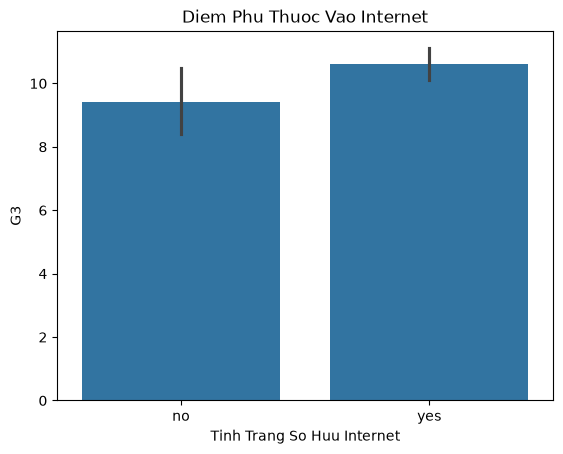

In [9]:
sb.barplot (data=df, x='internet', y='G3')
mpl.title('Diem Phu Thuoc Vao Internet')
mpl.xlabel('Tinh Trang So Huu Internet')
mpl.show()

Số lượng học sinh theo tình trạng học thêm

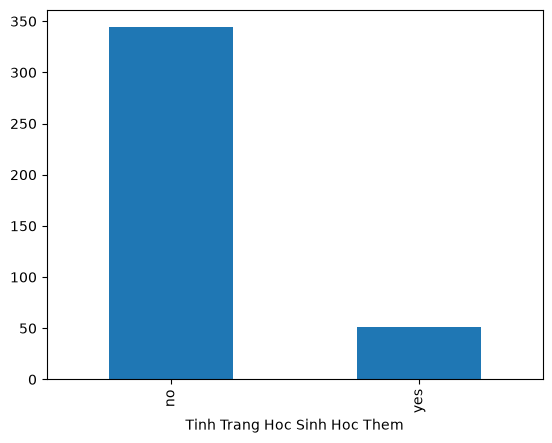

In [31]:
df['schoolsup'].value_counts().plot(kind='bar')
mpl.xlabel('Tinh Trang Hoc Sinh Hoc Them')
mpl.show()

 Phân bố điểm cuối kỳ (G3) của học sinh có dạng như thế nào? (chuẩn, 
lệch trái, lệch phải?)

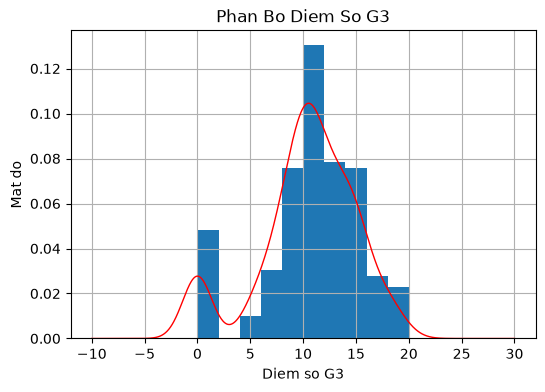

In [11]:
df['G3'].plot(
kind='hist',
bins=10,
figsize=(6, 4),
density=True
)
df['G3'].plot(kind='kde', color='red', linewidth=1)
mpl.title('Phan Bo Diem So G3')
mpl.xlabel('Diem so G3')
mpl.ylabel('Mat do')
mpl.grid(True)
mpl.show()

Phân bố độ tuổi của học sinh ra sao?

Text(0, 0.5, 'Tan suat hoc sinh')

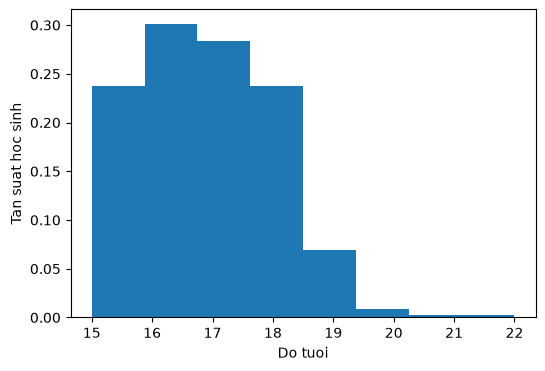

In [32]:
df['age'].plot(
kind='hist',
figsize=(6, 4),
bins=8,
density=True
)
mpl.xlabel('Do tuoi')
mpl.ylabel('Tan suat hoc sinh')

 Phân bố thời gian học mỗi tuần (studytime) như thế nào?

Text(0, 0.5, 'So luong hoc sinh')

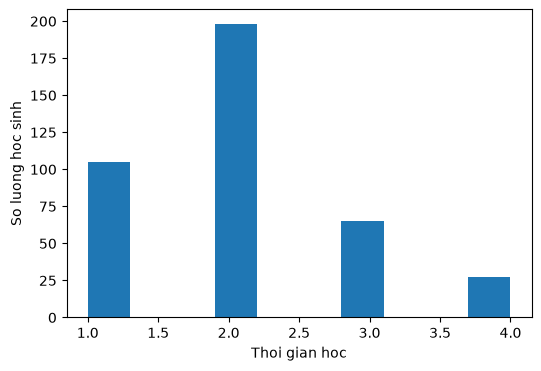

In [33]:
df['studytime'].plot(
kind='hist',
figsize=(6, 4),
bins=10,
)
mpl.xlabel('Thoi gian hoc')
mpl.ylabel('So luong hoc sinh')

 So sánh phân bố điểm G3 giữa nam và nữ (hue='sex’)

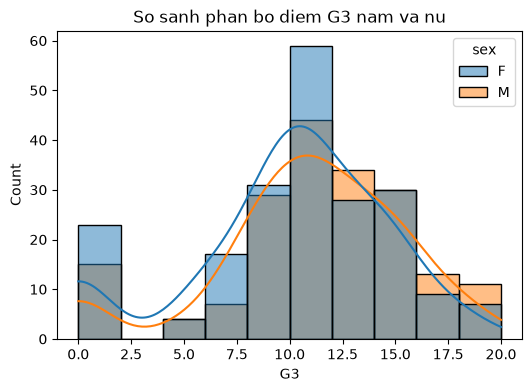

In [28]:
mpl.figure(figsize=(6, 4))
sb.histplot(data=df, x='G3', hue='sex', bins=10, kde=True)
mpl.title('So sanh phan bo diem G3 nam va nu')
mpl.show()

 So sánh điểm cuối kỳ (G3) giữa nam và nữ?

Text(0.5, 1.0, 'So sanh diem cuoi ki G3 giua Nam va Nu')

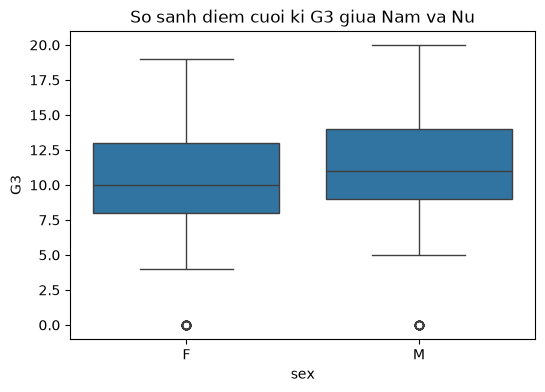

In [34]:
mpl.figure(figsize=(6,4))
sb.boxplot(data = df, x ='sex', y ='G3')
mpl.title('So sanh diem cuoi ki G3 giua Nam va Nu')

So sánh điểm G3 giữa các nhóm mức học của cha mẹ (Medu/Fedu)

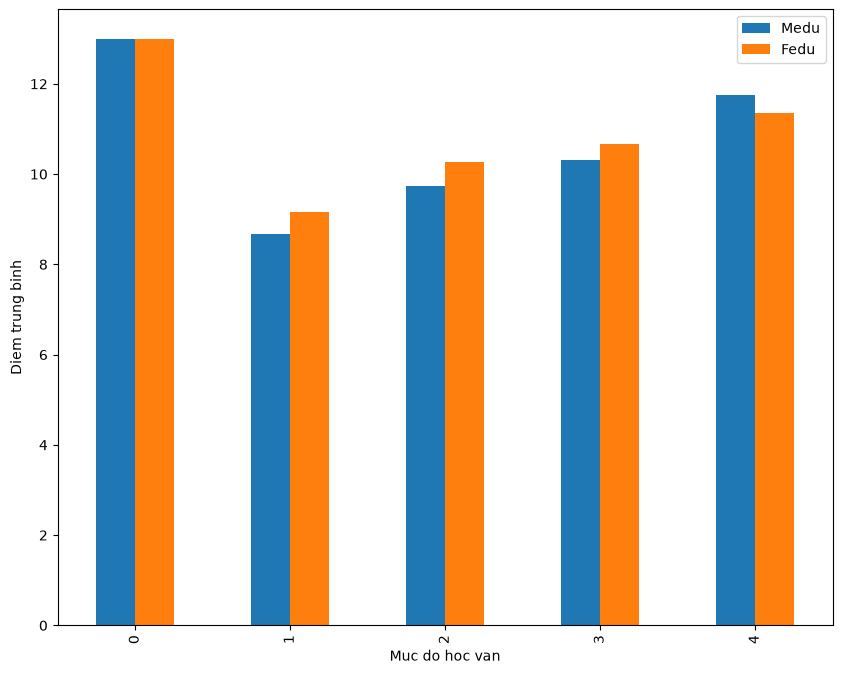

In [47]:
medu_gr = df.groupby('Medu')['G3'].mean()
fedu_gr = df.groupby('Fedu')['G3'].mean()

main_gr = pd.DataFrame({'Medu':medu_gr,'Fedu':fedu_gr})
main_gr.plot(kind = 'bar', figsize=(10, 8))
mpl.xlabel('Muc do hoc van')
mpl.ylabel('Diem trung binh')
mpl.show()


Ảnh hưởng của thời gian học (studytime) tới phân bố điểm G3

Text(0, 0.5, 'Diem cuoi ki')

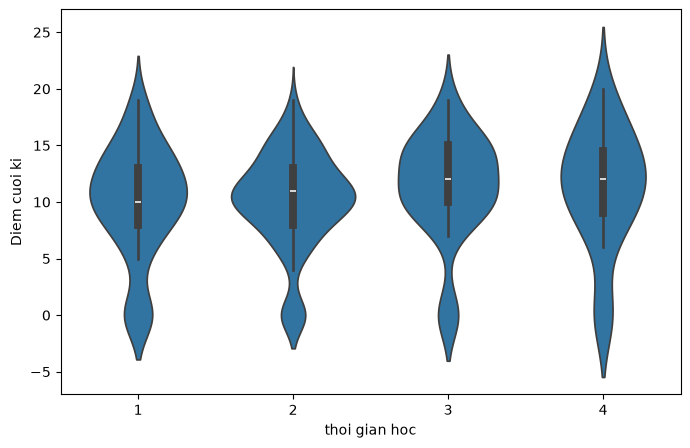

In [49]:
mpl.figure(figsize=(8,5))
sb.violinplot(data= df, x='studytime', y = 'G3')
mpl.xlabel('thoi gian hoc')
mpl.ylabel('Diem cuoi ki')


So sánh phân bố điểm G3 giữa học sinh có học thêm và không học 
thêm?

Text(0, 0.5, 'So luong')

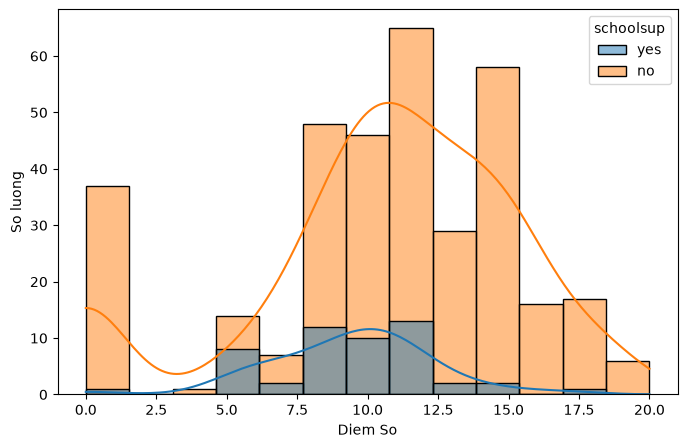

In [52]:
mpl.figure(figsize=(8,5))
sb.histplot(data = df, hue ='schoolsup', x='G3', kde = True)
mpl.xlabel('Diem So')
mpl.ylabel('So luong')

Giữa hai trường học (GP, MS) và giới tính (nam/nữ), điểm trung bình 
G1–G3 khác nhau thế nào?

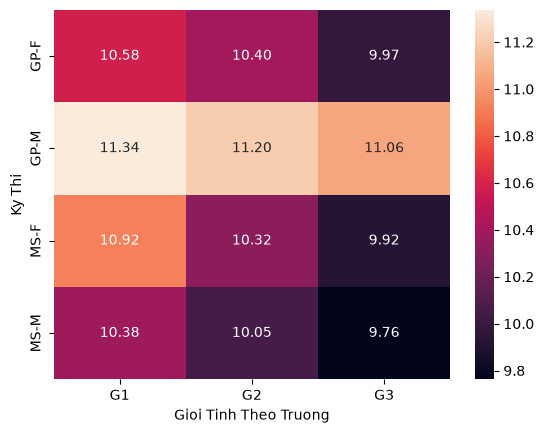

In [ ]:
fill = df.groupby(['school','sex'])[['G1','G2','G3']].mean()
sb.heatmap(fill, annot=True, fmt ='.2f')
mpl.xlabel('Ky Thi')
mpl.ylabel('Gioi Tinh Theo Truong')
mpl.show()

 Học sinh ở đô thị (U) hay nông thôn (R), có Internet hay không, đạt điểm 
trung bình cao hơn ở G1–G3?

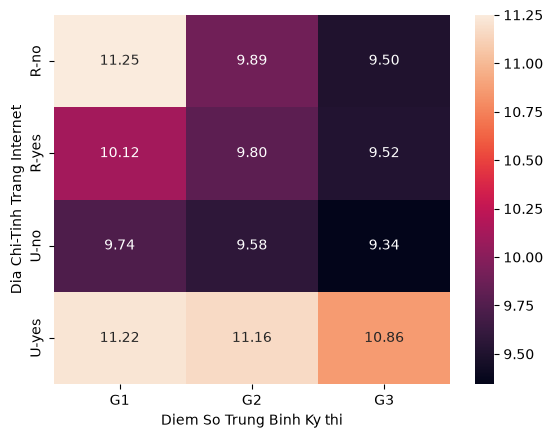

In [57]:
fill1 = df.groupby(['address','internet'])[['G1','G2','G3']].mean()
sb.heatmap(fill1, annot=True, fmt ='.2f')
mpl.xlabel('Diem So Trung Binh Ky thi')
mpl.ylabel('Dia Chi-Tinh Trang Internet')
mpl.show()


 Việc có học thêm ở trường (schoolsup) và được hỗ trợ học ở nhà 
(famsup) ảnh hưởng thế nào đến điểm G1–G3?

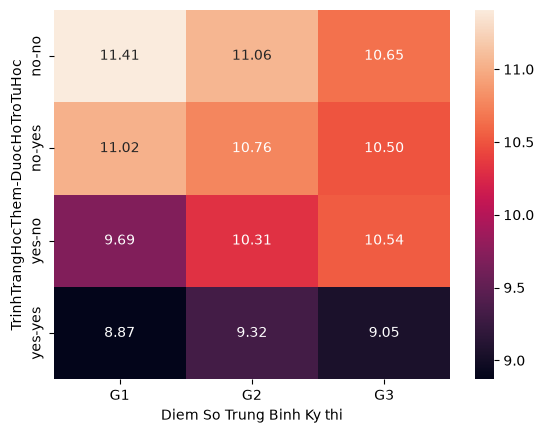

In [59]:
fill2 = df.groupby(['schoolsup','famsup'])[['G1','G2','G3']].mean()
sb.heatmap(fill2, annot=True, fmt ='.2f')
mpl.xlabel('Diem So Trung Binh Ky thi')
mpl.ylabel('TrinhTrangHocThem-DuocHoTroTuHoc')
mpl.show()

 Học sinh sống với cả cha mẹ (T) hay chỉ một người (A) có điểm học 
khác biệt thế nào, theo mức độ mối quan hệ trong gia đình (famrel)?

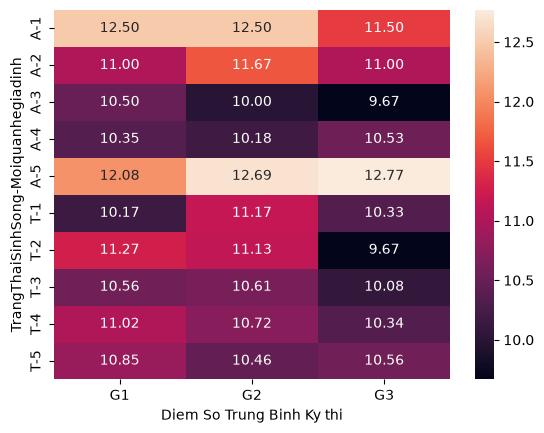

In [62]:
fill3 = df.groupby(['Pstatus','famrel'])[['G1','G2','G3']].mean()
sb.heatmap(fill3, annot=True, fmt ='.2f')
mpl.xlabel('Diem So Trung Binh Ky thi')
mpl.ylabel('TrangThaiSinhSong-Moiquanhegiadinh')
mpl.show()

Mối quan hệ giữa thời gian học và số lần trượt môn ảnh hưởng thế nào 
đến điểm G3?

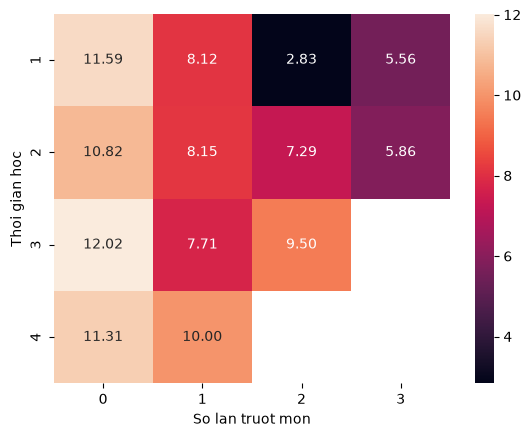

In [66]:
fill4 = df.groupby(["studytime", "failures"])["G3"].mean().unstack()
sb.heatmap(fill4, annot=True, fmt ='.2f')
mpl.xlabel('So lan truot mon')
mpl.ylabel('Thoi gian hoc')
mpl.show()
